# 1. Module 1: Graph-Based Hospital Navigation

In [1]:
from Graph import *
from LinkedList import *

In [2]:
corridors = [
    ("Emergency", "ICU", 2),
    ("Emergency", "Pharmacy", 4),
    ("ICU", "Radiology", 3),
    ("ICU", "Laboratory", 2),
    ("Pharmacy", "Wards", 5),
    ("Radiology", "Operating", 7),
    ("Laboratory", "Outpatient", 4),
    ("Operating", "Wards", 3),
    ("Outpatient", "Emergency", 8),  # this to form a cycle
    ("Wards", "Operating", 3),
    # Isolated node
    ("Parking", "Parking", 0),  # node without corridors
]
departments = {"Emergency", "ICU", "Pharmacy", "Radiology", "Laboratory", "Operating", "Wards", "Outpatient", "Parking"}

In [3]:
class EdgeWeightNode:
    def __init__(self, nodeA, nodeB, weight):
        self.nodeA = nodeA 
        self.nodeB = nodeB
        self.weight = weight

    def matches(self, u, v):
        return (self.nodeA == u and self.nodeB == v)

class EdgeWeightList:
    def __init__(self):
        self.weights = DSALinkedList()

    def addWeight(self, u, v, w):
        self.weights.insertLast(EdgeWeightNode(u, v, w))
        self.weights.insertLast(EdgeWeightNode(v, u, w))

    def getWeight(self, u, v):
        curr = self.weights.head
        while curr is not None:
            ewNode = curr.getValue()
            if ewNode.matches(u, v):
                return ewNode.weight
            curr = curr.getNext()
        return None

class HospitalGraph(DSAGraph):
    def __init__(self):
        super().__init__()
        self.weightList = EdgeWeightList()

    def addWeightedEdge(self, label1, label2, weight):
        self.addVertex(label1)
        self.addVertex(label2)
        self.addEdge(label1, label2)
        self.weightList.addWeight(label1, label2, weight)

    def getWeight(self, label1, label2):
        return self.weightList.getWeight(label1, label2)


In [4]:
hospital = HospitalGraph()
hospital.addWeightedEdge("Emergency", "ICU", 2)
hospital.addWeightedEdge("Emergency", "Radiology", 4)

print("Weight Emergency <-> ICU:", hospital.getWeight("Emergency", "ICU"))
print("Weight ICU <-> Emergency:", hospital.getWeight("ICU", "Emergency"))
print("Weight Emergency <-> Radiology:", hospital.getWeight("Emergency", "Radiology"))

Weight Emergency <-> ICU: 2
Weight ICU <-> Emergency: 2
Weight Emergency <-> Radiology: 4


In [5]:
class MapNode:
    def __init__(self, key, value):
        self.key = key
        self.value = value

class DSALinkedMap:
    def __init__(self):
        self.ll = DSALinkedList()

    def set(self, key, value):
        curr = self.ll.head
        while curr is not None:
            n = curr.getValue()
            if n.key == key:
                n.value = value
                return
            curr = curr.getNext()
        self.ll.insertLast(MapNode(key, value))

    def get(self, key):
        curr = self.ll.head
        while curr is not None:
            n = curr.getValue()
            if n.key == key:
                return n.value
            curr = curr.getNext()
        return None

    def has(self, key):
        curr = self.ll.head
        while curr is not None:
            n = curr.getValue()
            if n.key == key:
                return True
            curr = curr.getNext()
        return False

    def keys(self):
        curr = self.ll.head
        while curr is not None:
            yield curr.getValue().key
            curr = curr.getNext()

In [6]:
def bfs_group_by_level(graph, startLabel):
    # Output: departments grouped into DSALinkedList-of-DSALinkedList (hops)
    visited = DSALinkedMap()
    levels = DSALinkedMap()
    result = DSALinkedList()  # Each value is DSALinkedList of nodes for that level

    queue = DSAQueue()
    queue.enqueue(graph.getVertex(startLabel))
    visited.set(startLabel, True)
    levels.set(startLabel, 0)

    maxLevel = 0

    while not queue.isEmpty():
        currNode = queue.dequeue()
        currLabel = currNode.getLabel()
        currLevel = levels.get(currLabel)
        if currLevel > maxLevel:
            maxLevel = currLevel

        # Place in correct level bucket
        currLevelList = result.head
        levelFound = False
        levelIdx = 0
        for i in range(currLevel+1):
            if currLevelList is None:
                ll = DSALinkedList()
                result.insertLast(ll)
                currLevelList = result.tail
            currLevelList = currLevelList.getNext()

        levelList = result.head
        for i in range(currLevel):
            if levelList is not None:
                levelList = levelList.getNext()
        if levelList is not None:
            levelList.getValue().insertLast(currLabel)

        nbrs = currNode.getLinks().head
        while nbrs is not None:
            nNode = nbrs.getValue()
            nLabel = nNode.getLabel()
            if not visited.has(nLabel):
                queue.enqueue(nNode)
                visited.set(nLabel, True)
                levels.set(nLabel, currLevel+1)
            nbrs = nbrs.getNext()

    # Print level grouping
    print("BFS Groups by Level (hops):")
    levelPtr = result.head
    levelIdx = 0
    while levelPtr is not None:
        print("Level", levelIdx, ":", end=" ")
        levelList = levelPtr.getValue()
        nPtr = levelList.head
        while nPtr is not None:
            print(nPtr.getValue(), end=", ")
            nPtr = nPtr.getNext()
        print()
        levelPtr = levelPtr.getNext()
        levelIdx += 1

In [7]:
class CycleState:
    def __init__(self):
        self.foundCycle = False
        self.cycleStart = None
        self.cycleEnd = None
        
def dfs_detect_cycle(graph, startLabel):
    parentMap = DSALinkedMap()
    onPath = DSALinkedMap()
    state = CycleState()

    def visit(node, parent):
        label = node.getLabel()
        onPath.set(label, True)
        nbrs = node.getLinks().head
        while nbrs is not None:
            nbrNode = nbrs.getValue()
            nbrLabel = nbrNode.getLabel()
            if parent is not None and nbrLabel == parent.getLabel():
                nbrs = nbrs.getNext()
                continue
            if onPath.has(nbrLabel):
                # when a cycle is found
                state.foundCycle = True
                state.cycleStart = nbrLabel
                state.cycleEnd = label
                parentMap.set(nbrLabel, label)
                return True
            if not parentMap.has(nbrLabel):
                parentMap.set(nbrLabel, label)
                if visit(nbrNode, node):
                    return True
            nbrs = nbrs.getNext()
        onPath.set(label, False)
        return False

    root = graph.getVertex(startLabel)
    parentMap.set(startLabel, None)
    visit(root, None)
    print("DFS Cycle Detection:")
    if not state.foundCycle:
        print("No cycles found.")
    else:
        pathLL = DSALinkedList()
        curr = state.cycleEnd
        while curr != state.cycleStart:
            pathLL.insertFirst(curr)
            curr = parentMap.get(curr)
        pathLL.insertFirst(state.cycleStart)
        print("Cycle found: ", end=" ")
        p = pathLL.head
        while p is not None:
            print(p.getValue(), end=", ")
            p = p.getNext()
        print()

In [8]:
def a_star_shortest_path(graph, weightList, src, dst):
    pq = PriorityQueue()
    dist = DSALinkedMap()
    prev = DSALinkedMap()
    pq.enqueue(src, 0)
    dist.set(src, 0)
    prev.set(src, None)

    while not pq.isEmpty():
        curr, currCost = pq.dequeue()
        currLabel = curr
        if currLabel == dst:
            break
        node = graph.getVertex(currLabel)
        nbrs = node.getLinks().head
        while nbrs is not None:
            nbrNode = nbrs.getValue()
            nbrLabel = nbrNode.getLabel()
            w = weightList.getWeight(currLabel, nbrLabel)
            alt = dist.get(currLabel) + w
            if not dist.has(nbrLabel) or alt < dist.get(nbrLabel):
                dist.set(nbrLabel, alt)
                prev.set(nbrLabel, currLabel)
                pq.enqueue(nbrLabel, alt)  # heuristic=0
            nbrs = nbrs.getNext()

    # Reconstruct path
    pathLL = DSALinkedList()
    crawl = dst
    if not prev.has(dst):
        print("No path found")
        return
    while crawl is not None:
        pathLL.insertFirst(crawl)
        crawl = prev.get(crawl)
    print("Shortest path from", src, "to", dst, ": ", end="")
    p = pathLL.head
    while p is not None:
        print(p.getValue(), end=", ")
        p = p.getNext()
    print("\nTotal walking time:", dist.get(dst))

In [9]:
g = DSAGraph()
weightList = EdgeWeightList()
for d in departments:
    g.addVertex(d)
for u,v,w in corridors:
    if u != v:
        g.addEdge(u,v)
    weightList.addWeight(u, v, w)

bfs_group_by_level(g, "Emergency")
dfs_detect_cycle(g, "Emergency")
a_star_shortest_path(g, weightList, "Emergency", "Operating")

BFS Groups by Level (hops):
Level 0 : Emergency, 
Level 1 : ICU, Pharmacy, Outpatient, 
Level 2 : Radiology, Laboratory, Wards, 
Level 3 : Operating, 
DFS Cycle Detection:
Cycle found:  Emergency, ICU, Radiology, Operating, Wards, Pharmacy, 
Shortest path from Emergency to Operating : Emergency, ICU, Radiology, Operating, 
Total walking time: 12


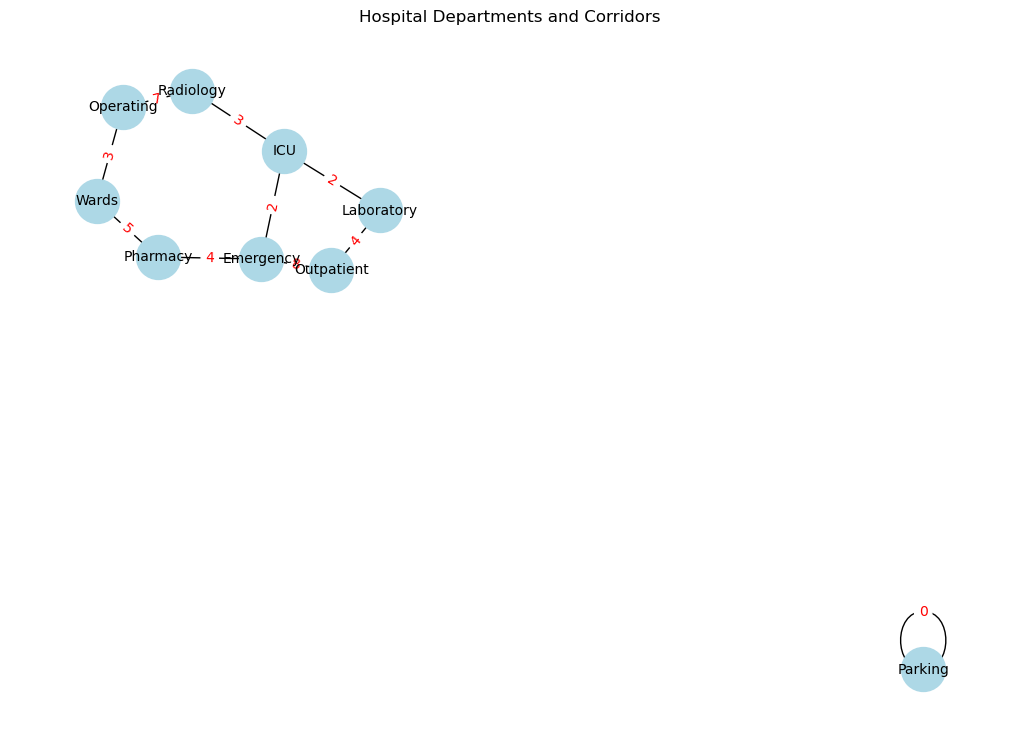

In [10]:
import networkx as nx
import matplotlib.pyplot as plt

# Create undirected weighted graph
G = nx.Graph()
for dept in departments:
    G.add_node(dept)
for u, v, w in corridors:
    G.add_edge(u, v, weight=w)

# Draw the graph
pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(10, 7))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=1000, font_size=10)
labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_color='red')

plt.title("Hospital Departments and Corridors")
plt.show()

# 2. Module 2: Hash-Based Patient Lookup

In [11]:
from HashTable import DSAHashTable
from LinkedList import *

class PatientRecord:
    def __init__(self, patient_id, name, age, department, urgency, status):
        if not str(patient_id).isdigit():
            raise ValueError("Patient ID must be an integer.")
        if not name or not name.strip():
            raise ValueError("Name cannot be empty.")
        try:
            urgency_int = int(urgency)
        except ValueError:
            raise ValueError("Urgency must be an integer 1-5.")
        if not (1 <= urgency_int <= 5):
            raise ValueError("Urgency must be 1-5.")
        self.patient_id = str(patient_id)
        self.name = name
        self.age = age
        self.department = department
        self.urgency = urgency_int
        self.status = status

    def __str__(self):
        return (str(self.patient_id) + "," + str(self.name) + "," +
                str(self.age) + "," + str(self.department) + "," +
                str(self.urgency) + "," + str(self.status))

class HashPatientRecords(DSAHashTable):
    def __init__(self, size=103):
        super().__init__(size)

    def insert(self, patientRecord):
        try:
            updated = self.has_key(patientRecord.patient_id)
            self.put(patientRecord.patient_id, patientRecord)
            if updated:
                print(f"Updated record for patient {patientRecord.patient_id}.")
            else:
                print(f"Inserted new record for patient {patientRecord.patient_id}.")
        except Exception as e:
            print(f"Insert error: {e}")

    def search(self, patientID):
        try:
            return self.get(patientID)
        except Exception as e:
            print(f"Search error: {e}")
            return None

    def delete(self, patientID):
        try:
            self.remove(patientID)
            print(f"Deleted record for patient {patientID}.")
        except Exception as e:
            print(f"Delete error: {e}")

    def load_csv(self, filename):
        import csv
        with open(filename, "r") as f:
            reader = csv.reader(f)
            header = next(reader)
            for row in reader:
                pid, name, age, dept, urg, status = row
                record = PatientRecord(pid, name, age, dept, urg, status)
                self.insert(record)

In [12]:
# Create the structure (uses prime >20 for best performance)
patients = HashPatientRecords(103) # Chaining/open addressing handled internally

# Load from CSV
patients.load_csv("patient_observations.csv")

# Single insert
rec1 = PatientRecord("1001", "Alex Smith", "23", "ICU", "3", "Waiting")
patients.insert(rec1)

# Search
result = patients.search("1001")
if result:
    print("Found:", result)

# Delete
patients.delete("1001")

# Search After Delete
result = patients.search("1001")
if result:
    print("Found:", result)

# Single insert
rec1 = PatientRecord("1001", "Alex Smith", "23", "ICU", "5", "Waiting")
patients.insert(rec1)

Inserted new record for patient 1000.
Inserted new record for patient 1001.
Inserted new record for patient 1002.
Inserted new record for patient 1003.
Inserted new record for patient 1004.
Inserted new record for patient 1005.
Inserted new record for patient 1006.
Inserted new record for patient 1007.
Inserted new record for patient 1008.
Inserted new record for patient 1009.
Inserted new record for patient 1010.
Inserted new record for patient 1011.
Inserted new record for patient 1012.
Inserted new record for patient 1013.
Inserted new record for patient 1014.
Inserted new record for patient 1015.
Inserted new record for patient 1016.
Inserted new record for patient 1017.
Inserted new record for patient 1018.
Inserted new record for patient 1019.
Inserted new record for patient 1020.
Inserted new record for patient 1021.
Inserted new record for patient 1022.
Inserted new record for patient 1023.
Inserted new record for patient 1024.
Inserted new record for patient 1025.
Inserted new

# 3. Module 3: Heaps

In [13]:
from Heaps import DSAHeap
from HashTable import DSAHashTable

# Emergency request for scheduling
class EmergencyRequest:
    def __init__(self, patient_id, expected_time):
        self.patient_id = patient_id
        self.expected_time = expected_time  # in minutes
        self.priority = None  # computed later
    
    def __str__(self):
        return f"PatientID: {self.patient_id}, ExpectedTime: {self.expected_time}, Priority: {self.priority}"

# Emergency Scheduler using Max Heap
class EmergencyScheduler:
    def __init__(self, maxSize, patientTable):
        self.heap = DSAHeap(maxSize)
        self.patientTable = patientTable  # DSAHashTable from Module 2
    
    def compute_priority(self, urgency, expected_time):
        # Priority = (6 - U) + 1000 / T
        if expected_time <= 0:
            raise ValueError("Expected treatment time must be positive.")
        return (6 - urgency) + (1000 / expected_time)
    
    def insert(self, patient_id, expected_time):
        # Validate patient
        try:
            patient = self.patientTable.get(patient_id)
        except Exception:
            print(f"Error: PatientID {patient_id} not found.")
            return
        if patient.status.lower() != "waiting" and patient.status.lower() != "critical":
            print(f"Error: Patient {patient_id} is not active (status: {patient.status}).")
            return
        if expected_time <= 0:
            print(f"Error: Invalid expected time for patient {patient_id}.")
            return
        priority = self.compute_priority(patient.urgency, expected_time)
        req = EmergencyRequest(patient_id, expected_time)
        req.priority = priority
        self.heap.add(priority, req)
        print(f"Inserted: {req} (U={patient.urgency}, T={expected_time}, Priority={priority:.2f})")
        self.heap.display()
    
    def peek(self):
        if self.heap.count == 0:
            print("Heap is empty.")
            return None
        entry = self.heap.heap[0] # because the heap is saved in an array, that is why .heap[0]
        print(f"Peek: {entry.getValue()} (Priority={entry.getPriority():.2f})")
        return entry.getValue()
    
    def extract_priority(self):
        if self.heap.count == 0:
            print("Heap is empty.")
            return None
        entry = self.heap.remove()
        req = entry.getValue()
        print(f"Extracted: {req} (Priority={entry.getPriority():.2f})")
        self.heap.display()
        return req
    
    def update(self, patient_id, new_urgency=None, new_expected_time=None):
        # Simple strategy: re-insert with new values (documented)
        try:
            patient = self.patientTable.get(patient_id)
        except Exception:
            print(f"Error: PatientID {patient_id} not found for update.")
            return
        if new_urgency is not None:
            patient.urgency = int(new_urgency)
        expected_time = new_expected_time if new_expected_time is not None else 30  # default
        self.insert(patient_id, expected_time)
        print(f"Update: Patient {patient_id} re-inserted with urgency {patient.urgency} and expected time {expected_time}.")


In [14]:
# --- Test Driver ---

# Setup patient table (simulate 10+ records)
patientTable = DSAHashTable(23)
patients = [
    PatientRecord("1001", "Alex Smith", 23, "ICU", 1, "Waiting"),
    PatientRecord("1002", "Taylor White", 42, "Radiology", 2, "Waiting"),
    PatientRecord("1003", "Jin Park", 35, "Emergency", 5, "Critical"),
    PatientRecord("1004", "Sam Lee", 29, "Wards", 3, "Waiting"),
    PatientRecord("1005", "Morgan Yu", 50, "ICU", 2, "Waiting"),
    PatientRecord("1006", "Chris Ray", 31, "Pharmacy", 4, "Waiting"),
    PatientRecord("1007", "Jamie Fox", 27, "Laboratory", 1, "Waiting"),
    PatientRecord("1008", "Pat Kim", 38, "Operating", 3, "Waiting"),
    PatientRecord("1009", "Lee Wong", 45, "Outpatient", 5, "Waiting"),
    PatientRecord("1010", "Dana Cruz", 33, "ICU", 2, "Waiting")
]
for p in patients:
    patientTable.put(p.patient_id, p)

scheduler = EmergencyScheduler(20, patientTable)

# Insert 10 requests (simulate different expected times)
insert_data = [
    ("1001", 30), ("1002", 45), ("1003", 20), ("1004", 60), ("1005", 25),
    ("1006", 50), ("1007", 15), ("1008", 40), ("1009", 70), ("1010", 35)
]
for pid, t in insert_data:
    scheduler.insert(pid, t)

# Extract 5 highest-priority cases
for _ in range(5):
    scheduler.extract_priority()

# Demonstrate update (change urgency for 1004, re-insert)
scheduler.update("1004", new_urgency=1, new_expected_time=22)

# Edge case: invalid PatientID
scheduler.insert("9999", 30)

# Edge case: zero treatment time
scheduler.insert("1001", 0)

# Edge case: inactive status
inactive_patient = PatientRecord("1011", "Inactive Pat", 40, "ICU", 2, "Treated")
patientTable.put("1011", inactive_patient)
scheduler.insert("1011", 30)

Inserted: PatientID: 1001, ExpectedTime: 30, Priority: 38.333333333333336 (U=1, T=30, Priority=38.33)

Inserted: PatientID: 1002, ExpectedTime: 45, Priority: 26.22222222222222 (U=2, T=45, Priority=26.22)

Inserted: PatientID: 1003, ExpectedTime: 20, Priority: 51.0 (U=5, T=20, Priority=51.00)

Inserted: PatientID: 1004, ExpectedTime: 60, Priority: 19.666666666666668 (U=3, T=60, Priority=19.67)

Inserted: PatientID: 1005, ExpectedTime: 25, Priority: 44.0 (U=2, T=25, Priority=44.00)

Inserted: PatientID: 1006, ExpectedTime: 50, Priority: 22.0 (U=4, T=50, Priority=22.00)

Inserted: PatientID: 1007, ExpectedTime: 15, Priority: 71.66666666666667 (U=1, T=15, Priority=71.67)

Inserted: PatientID: 1008, ExpectedTime: 40, Priority: 28.0 (U=3, T=40, Priority=28.00)

Inserted: PatientID: 1009, ExpectedTime: 70, Priority: 15.285714285714286 (U=5, T=70, Priority=15.29)

Inserted: PatientID: 1010, ExpectedTime: 35, Priority: 32.57142857142857 (U=2, T=35, Priority=32.57)

Extracted: PatientID: 1007, E

# 4. Module 4: Sorting Patient Records

In [15]:
import numpy as np
import time
from AdvancedSort import mergeSort, quickSortMedian3
from Emergency import EmergencyScheduler

def generate_patients_np(size, seed=42, disorder="random"):
    np.random.seed(seed)
    durations = np.random.randint(5, 180, size)
    if disorder == "nearly_sorted":
        durations = np.sort(durations)
        count = size // 10 if size >= 10 else 1
        idx1 = np.random.choice(np.arange(size), count, replace=False)
        idx2 = np.random.randint(0, size, count)
        for k in range(count):
            i = idx1[k]
            j = idx2[k]
            tmp = durations[i]
            durations[i] = durations[j]
            durations[j] = tmp
    elif disorder == "reversed":
        durations = np.sort(durations)[::-1]
    arr = np.empty(size, dtype=object)
    for i in range(size):
        rec = PatientRecord(f"{1000+i}", f"Name{i}", str(np.random.randint(20,90)), "ICU", np.random.randint(1,6), "Waiting")
        rec.duration = int(durations[i])
        arr[i] = rec
    return arr

# Create priority numpy array from PatientRecords using EmergencyScheduler's compute_priority
def priorities_from_patients(arr, scheduler):
    pri_arr = np.zeros(arr.size, dtype=float)
    for i in range(arr.size):
        patient = arr[i]
        pri_arr[i] = scheduler.compute_priority(patient.urgency, patient.duration)
    return pri_arr

# Rebuild record array sorted by priorities (stable, no lists)
def stable_patients_by_priority(sorted_priorities, original_patients):
    size = sorted_priorities.size
    sorted_arr = np.empty(size, dtype=object)
    used = np.zeros(size, dtype=bool)
    for i in range(size):
        v = sorted_priorities[i]
        for j in range(size):
            if not used[j]:
                patient = original_patients[j]
                priority = (6 - patient.urgency) + (1000 / patient.duration)
                if priority == v:
                    sorted_arr[i] = patient
                    used[j] = True
                    break
    return sorted_arr

def benchmark_sorts_np():
    sizes = np.array([10, 50, 100, 500, 1000, 5000, 10000])
    disorders = np.array(["random", "nearly_sorted", "reversed"])
    results_dtype = [('size', 'i4'), ('disorder', 'U14'), ('merge_time', 'f8'), ('quick_time', 'f8'), ('merge_ok', '?'), ('quick_ok', '?')]
    results = np.empty(sizes.size * disorders.size, dtype=results_dtype)
    idx = 0
    # Create a dummy scheduler for compute_priority
    dummy_table = DSAHashTable()
    scheduler = EmergencyScheduler(1, dummy_table)
    for si in range(sizes.size):
        for di in range(disorders.size):
            size = sizes[si]
            disorder = disorders[di]
            patients = generate_patients_np(size, seed=42, disorder=disorder)
            arr_merge = priorities_from_patients(patients, scheduler)
            t0 = time.time()
            mergeSort(arr_merge)
            t1 = time.time()
            sorted_merge = stable_patients_by_priority(arr_merge, patients)
            patients_copy = np.copy(patients)
            arr_quick = priorities_from_patients(patients_copy, scheduler)
            t2 = time.time()
            quickSortMedian3(arr_quick)
            t3 = time.time()
            sorted_quick = stable_patients_by_priority(arr_quick, patients_copy)
            merge_ok = True
            quick_ok = True
            for k in range(size-1):
                if sorted_merge[k] is not None and sorted_merge[k+1] is not None:
                    pri1 = (6 - sorted_merge[k].urgency) + (1000 / sorted_merge[k].duration)
                    pri2 = (6 - sorted_merge[k+1].urgency) + (1000 / sorted_merge[k+1].duration)
                    if pri1 > pri2:
                        merge_ok = False
                        break
            for k in range(size-1):
                if sorted_quick[k] is not None and sorted_quick[k+1] is not None:
                    pri1 = (6 - sorted_quick[k].urgency) + (1000 / sorted_quick[k].duration)
                    pri2 = (6 - sorted_quick[k+1].urgency) + (1000 / sorted_quick[k+1].duration)
                    if pri1 > pri2:
                        quick_ok = False
                        break
            results[idx] = (size, disorder, t1-t0, t3-t2, merge_ok, quick_ok)
            idx += 1
    print("\n| Size | Input Condition | MergeSort (s) | QuickSort (s) | Merge OK | Quick OK |")
    print("|------|----------------|---------------|--------------|----------|----------|")
    for i in range(results.size):
        r = results[i]
        print(f"| {r['size']:<4} | {r['disorder']:<14} | {r['merge_time']:<13.5f} | {r['quick_time']:<12.5f} | {str(r['merge_ok']):<8} | {str(r['quick_ok']):<8} |")

benchmark_sorts_np()


| Size | Input Condition | MergeSort (s) | QuickSort (s) | Merge OK | Quick OK |
|------|----------------|---------------|--------------|----------|----------|
| 10   | random         | 0.00002       | 0.00001      | True     | True     |
| 10   | nearly_sorted  | 0.00002       | 0.00001      | True     | True     |
| 10   | reversed       | 0.00030       | 0.00001      | True     | True     |
| 50   | random         | 0.00009       | 0.00014      | True     | True     |
| 50   | nearly_sorted  | 0.00032       | 0.00004      | True     | True     |
| 50   | reversed       | 0.00007       | 0.00023      | True     | True     |
| 100  | random         | 0.00016       | 0.00008      | True     | True     |
| 100  | nearly_sorted  | 0.00090       | 0.00019      | True     | True     |
| 100  | reversed       | 0.00043       | 0.00015      | True     | True     |
| 500  | random         | 0.00155       | 0.00064      | True     | True     |
| 500  | nearly_sorted  | 0.00107       | 0.00063